In [2]:
import tensorflow as tf
print("Tenorflow version:",tf.__version__)
gpus=tf.config.list_physical_devices("GPU")
print("GPUs found :",gpus)

Tenorflow version: 2.21.0
GPUs found : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
import os
import json

PROJECT_DIR = "/content/drive/MyDrive/leafscope-ai"

for folder in ["models", "data", "outputs"]:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

print("Project folder:", os.path.exists(PROJECT_DIR))
print("Models folder:", os.path.exists(f"{PROJECT_DIR}/models"))
print("Outputs folder:", os.path.exists(f"{PROJECT_DIR}/outputs"))

Project folder: True
Models folder: True
Outputs folder: True


In [4]:
!pip install -q -U kaggle
!kaggle datasets download -d abdallahalidev/plantvillage-dataset -p /content/data --unzip

Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0
100% 2.04G/2.04G [00:23<00:00, 91.8MB/s]



In [5]:
from google.colab import userdata
import os

os.environ["KAGGLE_API_TOKEN"]= userdata.get("KAGGLE_API_TOKEN")
print("Token loaded:",len(os.environ["KAGGLE_API_TOKEN"])>0)

Token loaded: True


In [6]:
import os

DATA_ROOT = "/content/data/plantvillage dataset/color"

class_names = sorted(
    folder for folder in os.listdir(DATA_ROOT)
    if os.path.isdir(os.path.join(DATA_ROOT, folder))
)

print("Total classes:", len(class_names))
print(class_names[:5])

Total classes: 38
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']


In [7]:
print("class_names exists:", "class_names" in globals())

class_names exists: True


In [8]:
import json
import os

with open(f"{PROJECT_DIR}/models/class_names.json", "w") as f:
    json.dump(class_names, f, indent=2)

print("Saved:", os.path.exists(
    f"{PROJECT_DIR}/models/class_names.json"
))

Saved: True


In [9]:
import os

print("Drive accessible:", os.path.exists("/content/drive/MyDrive"))
print("Project folder:", os.path.exists("/content/drive/MyDrive/leafscope-ai"))

Drive accessible: True
Project folder: True


In [10]:
print("Data folder exists:", os.path.exists("/content/data"))

if os.path.exists("/content/data"):
    print("Contents:", os.listdir("/content/data"))

Data folder exists: True
Contents: ['plantvillage dataset']


In [11]:
import os

DATA_ROOT = "/content/data/plantvillage dataset"

print("Dataset contents:", os.listdir(DATA_ROOT))

color_path = os.path.join(DATA_ROOT, "color")
print("Color folder exists:", os.path.exists(color_path))

if os.path.exists(color_path):
    print("Number of classes:", len(os.listdir(color_path)))
    print("First 5 folders:", os.listdir(color_path)[:5])

Dataset contents: ['color', 'grayscale', 'segmented']
Color folder exists: True
Number of classes: 38
First 5 folders: ['Apple___Apple_scab', 'Pepper,_bell___Bacterial_spot', 'Tomato___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Apple___Black_rot']


In [12]:
PROJECT_DIR = "/content/drive/MyDrive/leafscope-ai"

for sub in ["models", "data", "outputs"]:
    os.makedirs(f"{PROJECT_DIR}/{sub}", exist_ok=True)

print("Project folders ready at:", PROJECT_DIR)

Project folders ready at: /content/drive/MyDrive/leafscope-ai


In [13]:
import json

DATA_ROOT = "/content/data/plantvillage dataset/color"

class_names = sorted(
    folder for folder in os.listdir(DATA_ROOT)
    if os.path.isdir(os.path.join(DATA_ROOT, folder))
)

PROJECT_DIR = "/content/drive/MyDrive/leafscope-ai"

with open(f"{PROJECT_DIR}/models/class_names.json", "w") as f:
    json.dump(class_names, f, indent=2)

print("Total classes:", len(class_names))
print("JSON saved:", os.path.exists(
    f"{PROJECT_DIR}/models/class_names.json"
))

Total classes: 38
JSON saved: True


In [14]:
import os

OUTPUT_DIR = "/content/drive/MyDrive/leafscope-ai/outputs"

print("PNG files in outputs folder:")

png_files = [
    f for f in os.listdir(OUTPUT_DIR)
    if f.lower().endswith(".png")
]

if png_files:
    for file in png_files:
        print("✅", file)
else:
    print("❌ No PNG files found")

PNG files in outputs folder:
❌ No PNG files found


In [15]:
!ls /content/data
!ls "/content/data/plantvillage dataset"

'plantvillage dataset'
color  grayscale  segmented


In [16]:
import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from collections import Counter
from tqdm import tqdm

DATA_ROOT = "/content/data/plantvillage dataset/color"

class_names = sorted(os.listdir(DATA_ROOT))
print("Number of classes:", len(class_names))

total_images = 0
for cls in class_names:
    count = len(os.listdir(os.path.join(DATA_ROOT, cls)))
    total_images += count

print("Total images:", total_images)
print("First 5 classes:", class_names[:5])

Number of classes: 38
Total images: 54305
First 5 classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']


In [17]:
records = []
for cls in class_names:
    folder = os.path.join(DATA_ROOT, cls)
    for fname in os.listdir(folder):
        if fname.lower().endswith((".jpg", ".jpeg", ".png")):
            records.append({"path": os.path.join(folder, fname), "class": cls})

df = pd.DataFrame(records)
df["crop"] = df["class"].str.split("___").str[0]
df["condition"] = df["class"].str.split("___").str[1]
df["is_healthy"] = df["condition"].str.lower().eq("healthy")

print("Table shape:", df.shape)
df.head()

Table shape: (54305, 5)


,path,class,crop,condition,is_healthy
0,/content/data/plantvillage dataset/color/Apple...,Apple___Apple_scab,Apple,Apple_scab,False
1,/content/data/plantvillage dataset/color/Apple...,Apple___Apple_scab,Apple,Apple_scab,False
2,/content/data/plantvillage dataset/color/Apple...,Apple___Apple_scab,Apple,Apple_scab,False
3,/content/data/plantvillage dataset/color/Apple...,Apple___Apple_scab,Apple,Apple_scab,False
4,/content/data/plantvillage dataset/color/Apple...,Apple___Apple_scab,Apple,Apple_scab,False


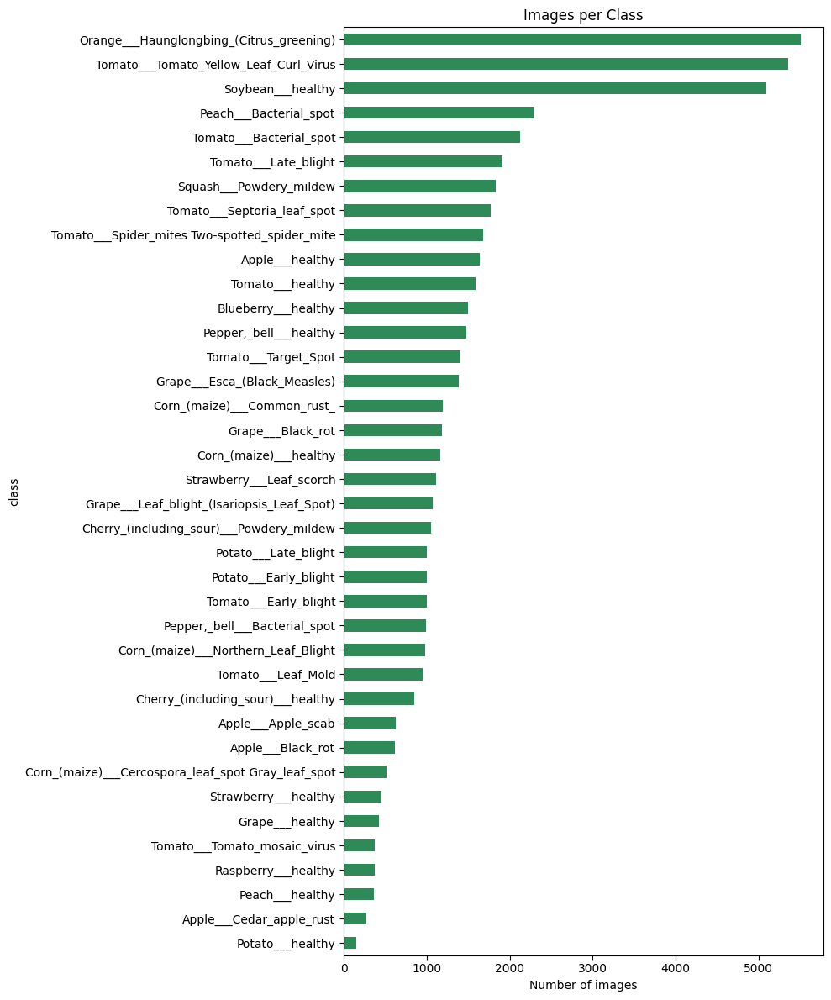

Largest class : Orange___Haunglongbing_(Citrus_greening) -> 5507
Smallest class: Potato___healthy -> 152
Imbalance ratio: 36.2


In [18]:
counts = df["class"].value_counts().sort_values()

plt.figure(figsize=(10, 12))
counts.plot(kind="barh", color="seagreen")
plt.title("Images per Class")
plt.xlabel("Number of images")
plt.tight_layout()
plt.savefig(f"{PROJECT_DIR}/outputs/class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print("Largest class :", counts.idxmax(), "->", counts.max())
print("Smallest class:", counts.idxmin(), "->", counts.min())
print("Imbalance ratio:", round(counts.max() / counts.min(), 1))

class
Potato___healthy            152
Apple___Cedar_apple_rust    275
Peach___healthy             360
Name: count, dtype: int64
class
Soybean___healthy                           5090
Tomato___Tomato_Yellow_Leaf_Curl_Virus      5357
Orange___Haunglongbing_(Citrus_greening)    5507
Name: count, dtype: int64
Imbalance ratio: 36.2


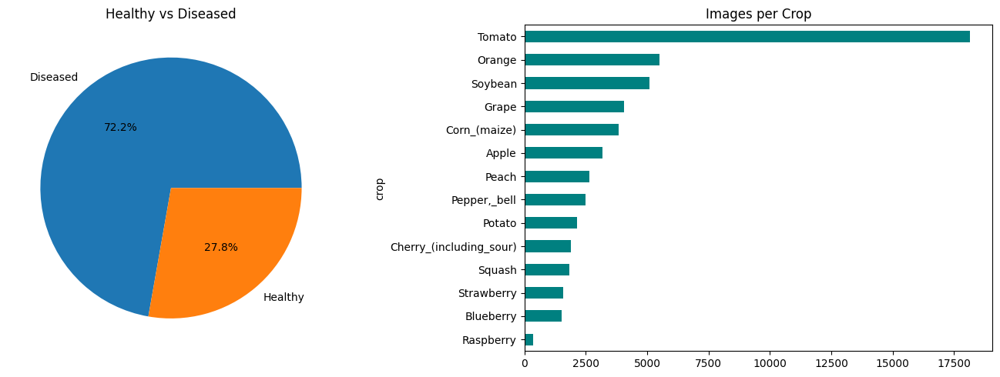

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df["is_healthy"].map({True: "Healthy", False: "Diseased"}).value_counts().plot(
    kind="pie", autopct="%1.1f%%", ax=axes[0])
axes[0].set_title("Healthy vs Diseased")
axes[0].set_ylabel("")

df["crop"].value_counts().sort_values().plot(kind="barh", ax=axes[1], color="teal")
axes[1].set_title("Images per Crop")
print(counts.head(3))
print(counts.tail(3))
print("Imbalance ratio:", round(counts.max() / counts.min(), 1))

plt.tight_layout()
plt.savefig(f"{PROJECT_DIR}/outputs/crop_and_health.png", dpi=150, bbox_inches="tight")
plt.show()

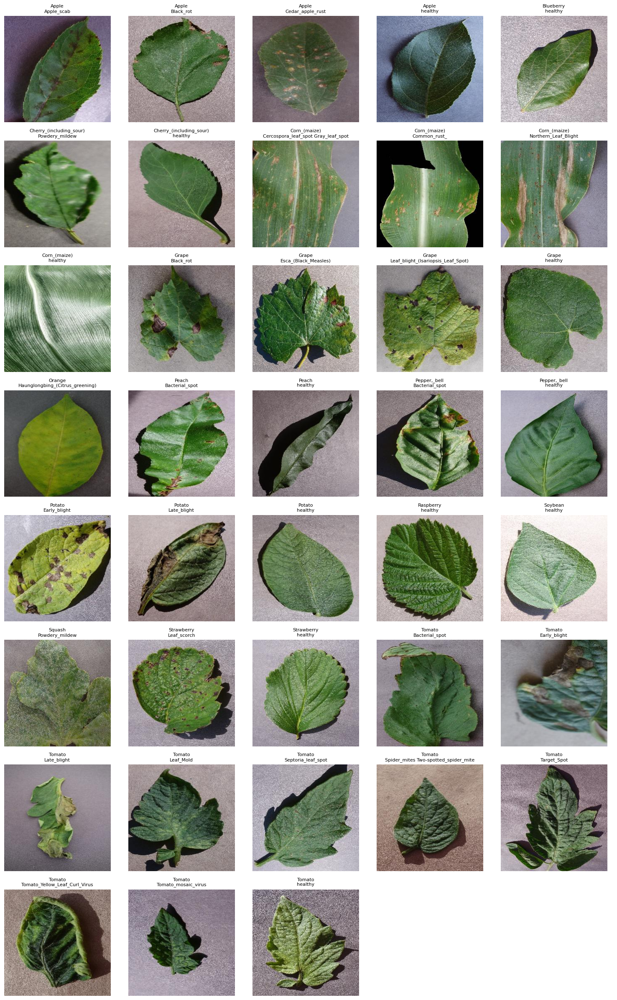

In [20]:
SEED=42
fig, axes = plt.subplots(8, 5, figsize=(15, 24))

for ax, cls in zip(axes.flat, class_names):
    row = df[df["class"] == cls].sample(1, random_state=SEED).iloc[0]
    ax.imshow(Image.open(row["path"]))
    ax.set_title(cls.replace("___", "\n"), fontsize=8)
    ax.axis("off")

for ax in axes.flat[len(class_names):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig(f"{PROJECT_DIR}/outputs/sample_grid.png", dpi=120, bbox_inches="tight")
plt.show()

Image sizes : [((256, 256), 1000)]
Image modes : Counter({'RGB': 1000})


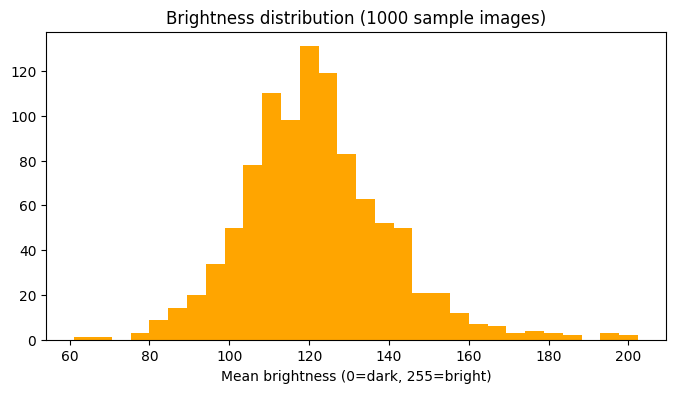

In [21]:
sample = df.sample(1000, random_state=SEED)
sizes, modes, brightness = [], [], []

for p in sample["path"]:
    with Image.open(p) as im:
        sizes.append(im.size)
        modes.append(im.mode)
        brightness.append(np.asarray(im.convert("L")).mean())

print("Image sizes :", Counter(sizes).most_common(5))
print("Image modes :", Counter(modes))

plt.figure(figsize=(8, 4))
plt.hist(brightness, bins=30, color="orange")
plt.title("Brightness distribution (1000 sample images)")
plt.xlabel("Mean brightness (0=dark, 255=bright)")
plt.savefig(f"{PROJECT_DIR}/outputs/brightness.png", dpi=150, bbox_inches="tight")
plt.show()

In [22]:
from tqdm import tqdm

bad_files = []
for p in tqdm(df["path"]):
    try:
        with Image.open(p) as im:
            im.verify()
    except Exception:
        bad_files.append(p)

print("Corrupt images:", len(bad_files))
print(bad_files[:5])

100%|██████████| 54305/54305 [00:09<00:00, 5564.28it/s]

Corrupt images: 0
[]


In [23]:
counts.sort_index().rename("num_images").to_csv(
    f"{PROJECT_DIR}/outputs/class_counts.csv", index_label="class")

with open(f"{PROJECT_DIR}/models/class_names.json", "w") as f:
    json.dump(class_names, f, indent=2)

print("Saved: class_counts.csv and class_names.json")

Saved: class_counts.csv and class_names.json


In [24]:
import os

PROJECT_DIR = "/content/drive/MyDrive/leafscope-ai"

print("=== MODELS FOLDER ===")
models_path = f"{PROJECT_DIR}/models"

if os.path.exists(models_path):
    print(os.listdir(models_path))
else:
    print("Models folder not found")

print("\n=== OUTPUTS FOLDER ===")
outputs_path = f"{PROJECT_DIR}/outputs"

if os.path.exists(outputs_path):
    print(os.listdir(outputs_path))
else:
    print("Outputs folder not found")

=== MODELS FOLDER ===
['class_names.json']

=== OUTPUTS FOLDER ===
['crop_and_health.png', 'class_counts.csv', 'class_distribution.png', 'sample_grid.png', 'brightness.png']


In [25]:
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

tf.random.set_seed(SEED)

class_to_idx = {name: i for i, name in enumerate(class_names)}
df["label"] = df["class"].map(class_to_idx)

print("Classes:", len(class_to_idx))
print("Label range:", df["label"].min(), "to", df["label"].max())
print("Any missing labels:", df["label"].isna().any())

Classes: 38
Label range: 0 to 37
Any missing labels: False


In [26]:
train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df["label"], random_state=SEED)

val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)

train_df = train_df.assign(split="train")
val_df = val_df.assign(split="val")
test_df = test_df.assign(split="test")

print("Train:", len(train_df), "| Val:", len(val_df), "| Test:", len(test_df))

Train: 38013 | Val: 8146 | Test: 8146


In [27]:
all_split = pd.concat([train_df, val_df, test_df])
table = all_split.groupby(["class", "split"]).size().unstack()

print(table.sort_values("train").head(5))
print("Min images per class -> train:", table["train"].min(),
      "| val:", table["val"].min(), "| test:", table["test"].min())

assert set(train_df["path"]).isdisjoint(val_df["path"])
assert set(train_df["path"]).isdisjoint(test_df["path"])
assert set(val_df["path"]).isdisjoint(test_df["path"])
print("No overlap between splits: OK")

all_split[["path", "class", "label", "split"]].to_csv(
    f"{PROJECT_DIR}/data/splits.csv", index=False)
print("Saved splits.csv")

split                         test  train  val
class                                         
Potato___healthy                23    106   23
Apple___Cedar_apple_rust        41    193   41
Peach___healthy                 54    252   54
Raspberry___healthy             55    260   56
Tomato___Tomato_mosaic_virus    56    261   56
Min images per class -> train: 106 | val: 23 | test: 23
No overlap between splits: OK
Saved splits.csv


In [28]:
classes = np.arange(len(class_names))
balanced = compute_class_weight(
    class_weight="balanced", classes=classes, y=train_df["label"].values)

class_weight_full = {int(i): float(balanced[i]) for i in classes}
class_weight_soft = {int(i): float(np.sqrt(balanced[i])) for i in classes}

for name, cw in [("full", class_weight_full), ("soft", class_weight_soft)]:
    vals = list(cw.values())
    print(f"{name}: min={min(vals):.2f}, max={max(vals):.2f}")

lo = min(class_weight_full, key=class_weight_full.get)
hi = max(class_weight_full, key=class_weight_full.get)
print("Lowest weight class :", class_names[lo])
print("Highest weight class:", class_names[hi])

with open(f"{PROJECT_DIR}/data/class_weights.json", "w") as f:
    json.dump({"full": class_weight_full, "soft": class_weight_soft}, f, indent=2)
print("Saved class_weights.json")

full: min=0.26, max=9.44
soft: min=0.51, max=3.07
Lowest weight class : Orange___Haunglongbing_(Citrus_greening)
Highest weight class: Potato___healthy
Saved class_weights.json


Augmentation + Data Pipeline


In [29]:
data_augmentation = keras.Sequential([
    keras.layers.RandomFlip("horizontal_and_vertical"),
    keras.layers.RandomRotation(0.15),
    keras.layers.RandomZoom(0.15),
    keras.layers.RandomBrightness(0.1),
    keras.layers.RandomContrast(0.15),
], name="data_augmentation")


def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, label


def make_dataset(frame, training):
    paths = frame["path"].tolist()
    labels = frame["label"].values.astype("int32")
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    if training:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                    num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

Create Datasets and Check Batch

In [30]:
import time

CACHE_DIR = "/content/cache"
os.makedirs(CACHE_DIR, exist_ok=True)

def load_image_u8(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.cast(tf.round(img), tf.uint8)
    return img, label

def make_fast_dataset(frame, name, training):
    paths = frame["path"].tolist()
    labels = frame["label"].values.astype("int32")
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image_u8, num_parallel_calls=AUTOTUNE)
    ds = ds.cache(f"{CACHE_DIR}/{name}")
    if training:
        ds = ds.shuffle(2048, seed=SEED)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_fast_dataset(train_df, "train", training=True)
val_ds = make_fast_dataset(val_df, "val", training=False)
test_ds = make_fast_dataset(test_df, "test", training=False)

for name, d in [("train", train_ds), ("val", val_ds), ("test", test_ds)]:
    t0 = time.time()
    n = 0
    for xb, yb in d:
        n += len(xb)
    print(f"{name}: {n} images cached in {time.time() - t0:.0f} s")

train: 38013 images cached in 79 s
val: 8146 images cached in 17 s
test: 8146 images cached in 18 s


Augmentation Preview

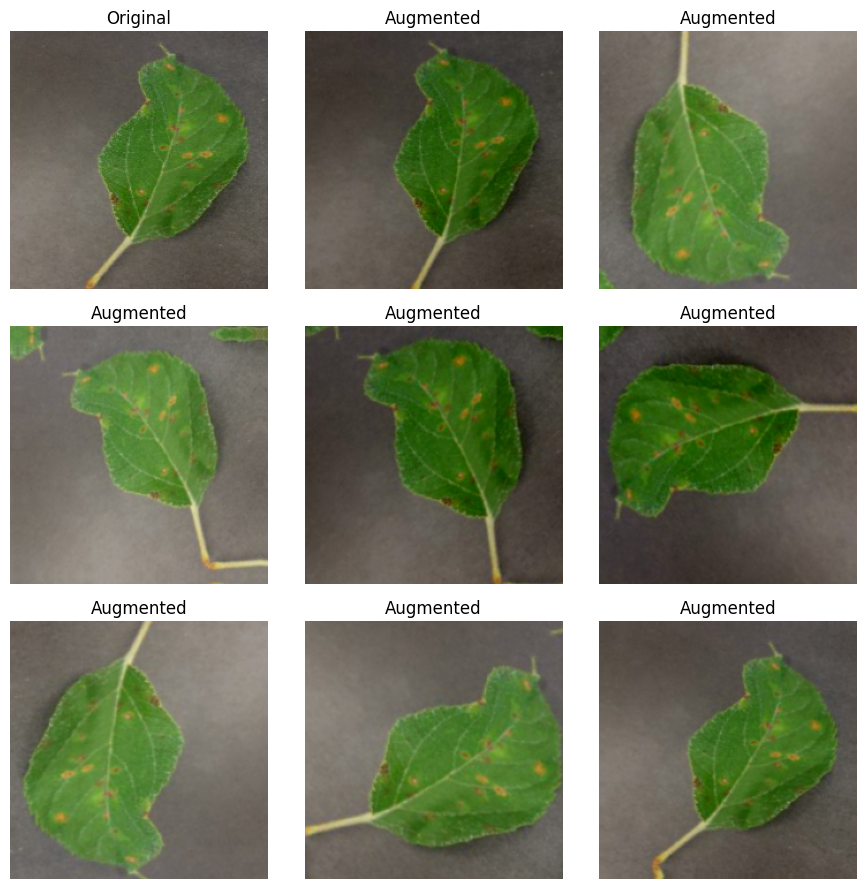

Class: Apple___Cedar_apple_rust


In [31]:
sample_path = train_df.iloc[0]["path"]
img, _ = load_image(sample_path, 0)
img_batch = tf.expand_dims(img, 0)

fig, axes = plt.subplots(3, 3, figsize=(9, 9))
axes[0, 0].imshow(np.clip(img.numpy(), 0, 255).astype("uint8"))
axes[0, 0].set_title("Original")

for ax in axes.flat[1:]:
    aug = data_augmentation(img_batch, training=True)[0]
    ax.imshow(np.clip(aug.numpy(), 0, 255).astype("uint8"))
    ax.set_title("Augmented")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.savefig(f"{PROJECT_DIR}/outputs/augmentation_preview.png", dpi=120, bbox_inches="tight")
plt.show()
print("Class:", train_df.iloc[0]["class"])

Save Config

In [32]:
config = {
    "img_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "seed": SEED,
    "num_classes": len(class_names),
    "split": {"train": len(train_df), "val": len(val_df), "test": len(test_df)},
    "preprocessing_note": "Images are resized to 224x224 RGB with pixel values 0-255. The model applies its own preprocess_input internally.",
}

with open(f"{PROJECT_DIR}/models/preprocess_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("Saved preprocess_config.json")

Saved preprocess_config.json


In [33]:
keras.mixed_precision.set_global_policy("mixed_float16")
print("Policy:", keras.mixed_precision.global_policy().name)

def build_mobilenetv2_fast(num_classes, img_size=224, dropout=0.3):
    base_model = keras.applications.MobileNetV2(
        input_shape=(img_size, img_size, 3), include_top=False, weights="imagenet")
    base_model.trainable = False

    inputs = keras.Input(shape=(img_size, img_size, 3), name="image")
    x = data_augmentation(inputs)
    x = keras.layers.Rescaling(scale=1/127.5, offset=-1, name="preprocess")(x)
    x = base_model(x, training=False)
    x = keras.layers.GlobalAveragePooling2D(name="gap")(x)
    x = keras.layers.Dropout(dropout, name="dropout")(x)
    outputs = keras.layers.Dense(num_classes, activation="softmax",
                                 dtype="float32", name="predictions")(x)
    return keras.Model(inputs, outputs, name="leafscope_mobilenetv2"), base_model

model, base_model = build_mobilenetv2_fast(len(class_names), IMG_SIZE)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy",
             keras.metrics.SparseTopKCategoricalAccuracy(k=3, name="top3_acc")],
)

trainable = int(np.sum([np.prod(w.shape) for w in model.trainable_weights]))
print("Model built. Trainable params:", f"{trainable:,}")

try:
    mlflow.end_run()
except Exception:
    pass

Policy: mixed_float16
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Model built. Trainable params: 48,678


In [34]:
model.summary()

trainable = int(np.sum([np.prod(w.shape) for w in model.trainable_weights]))
non_trainable = int(np.sum([np.prod(w.shape) for w in model.non_trainable_weights]))
print("Trainable params    :", f"{trainable:,}")
print("Non-trainable params:", f"{non_trainable:,}")

with open(f"{PROJECT_DIR}/outputs/model_summary_mobilenetv2.txt", "w") as f:
    model.summary(print_fn=lambda line: f.write(line + "\n"))
print("Saved model_summary_mobilenetv2.txt")

Model: "leafscope_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocess (Rescaling)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Trainable params    : 48,678
Non-trainable params: 2,257,984


Saved model_summary_mobilenetv2.txt


In [35]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.SparseTopKCategoricalAccuracy(k=3, name="top3_acc"),
    ],
)
print("Model compiled.")

Model compiled.


In [36]:
images, labels = next(iter(val_ds))
probs = model.predict(images, verbose=0)

print("Output shape:", probs.shape)
print("Row sums (should be ~1):", probs.sum(axis=1)[:3])
print("Predicted classes:", probs.argmax(axis=1)[:5])

results = model.evaluate(val_ds.take(5), verbose=0, return_dict=True)
print("Before training ->", {k: round(float(v), 3) for k, v in results.items()})
print("Random-guess loss would be about:", round(float(np.log(len(class_names))), 2))
print("Random-guess accuracy would be about:", round(1 / len(class_names), 3))

Output shape: (32, 38)
Row sums (should be ~1): [1.        1.        1.0000001]
Predicted classes: [30 30 30 35 30]
Before training -> {'accuracy': 0.019, 'loss': 3.769, 'top3_acc': 0.094}
Random-guess loss would be about: 3.64
Random-guess accuracy would be about: 0.026


In [37]:
import os

print("GPU:", tf.config.list_physical_devices("GPU"))
print("Train / Val / Test:", len(train_df), len(val_df), len(test_df))

images, labels = next(iter(train_ds))
print("Train batch:", images.shape, images.dtype)
print("Pixel range:", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))

print("Soft class weights:", round(min(class_weight_soft.values()), 2),
      "to", round(max(class_weight_soft.values()), 2))

for fname in ["data/splits.csv", "data/class_weights.json",
              "models/class_names.json", "models/preprocess_config.json"]:
    print(fname, "->", os.path.exists(f"{PROJECT_DIR}/{fname}"))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Train / Val / Test: 38013 8146 8146
Train batch: (32, 224, 224, 3) <dtype: 'float32'>
Pixel range: 0.0 to 252.0
Soft class weights: 0.51 to 3.07
data/splits.csv -> True
data/class_weights.json -> True
models/class_names.json -> True
models/preprocess_config.json -> True


In [38]:
!pip install -q mlflow


Training

In [39]:
import time

CKPT_DIR = f"{PROJECT_DIR}/models/checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)

USE_MLFLOW = True
try:
    import mlflow
    mlflow.set_tracking_uri(f"file:{PROJECT_DIR}/mlruns")
    mlflow.set_experiment("leafscope-ai")
    print("MLflow ready:", mlflow.get_tracking_uri())
except Exception as e:
    USE_MLFLOW = False
    print("MLflow not available, continuing without it:", e)


class MlflowLogger(keras.callbacks.Callback):
    def __init__(self, prefix=""):
        super().__init__()
        self.prefix = prefix

    def on_epoch_end(self, epoch, logs=None):
        if USE_MLFLOW and logs:
            metrics = {f"{self.prefix}{k}": float(v) for k, v in logs.items()}
            mlflow.log_metrics(metrics, step=epoch)

MLflow not available, continuing without it: The filesystem tracking backend (e.g., './mlruns') is in maintenance mode and will not receive further updates. Please migrate to a database backend (e.g., 'sqlite:///mlflow.db') to access the latest MLflow features. The `mlflow migrate-filestore` tool migrates your existing data losslessly. See https://mlflow.org/docs/latest/self-hosting/migrate-from-file-store for migration guidance. If the filesystem backend is required for your workflow, set `MLFLOW_ALLOW_FILE_STORE=true` to opt out of this exception.


In [40]:
STAGE_A_EPOCHS = 8

callbacks_a = [
    keras.callbacks.ModelCheckpoint(
        f"{CKPT_DIR}/stageA_best.keras", monitor="val_loss",
        mode="min", save_best_only=True, verbose=1),
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=1, min_lr=1e-5, verbose=1),
    MlflowLogger(prefix="stageA_"),
]

if USE_MLFLOW:
    mlflow.start_run(run_name="mobilenetv2_v1")
    mlflow.log_params({
        "model": "MobileNetV2", "img_size": IMG_SIZE, "batch_size": BATCH_SIZE,
        "dropout": 0.3, "class_weights": "soft (sqrt of balanced)",
        "stageA_lr": 1e-3, "stageA_max_epochs": STAGE_A_EPOCHS,
    })

t0 = time.time()
history_a = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=STAGE_A_EPOCHS,
    class_weight=class_weight_soft,
    callbacks=callbacks_a,
)
print(f"Stage A time: {(time.time() - t0) / 60:.1f} minutes")

Epoch 1/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.6977 - loss: 1.1714 - top3_acc: 0.8394
Epoch 1: val_loss improved from None to 0.33419, saving model to /content/drive/MyDrive/leafscope-ai/models/checkpoints/stageA_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/leafscope-ai/models/checkpoints/stageA_best.keras
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 110s 82ms/step - accuracy: 0.8112 - loss: 0.6935 - top3_acc: 0.9304 - val_accuracy: 0.8996 - val_loss: 0.3342 - val_top3_acc: 0.9813 - learning_rate: 0.0010
Epoch 2/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.8934 - loss: 0.3548 - top3_acc: 0.9774
Epoch 2: val_loss improved from 0.33419 to 0.28180, saving model to /content/drive/MyDrive/leafscope-ai/models/checkpoints/stageA_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/leafscope-ai/models/checkpoints/stageA_best.keras
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 87s 73ms/step - accuracy: 0.8940 - loss: 0.3465 - top3_acc: 0.9778 - val

In [41]:
best_a_acc = max(history_a.history["val_accuracy"])
best_a_loss = min(history_a.history["val_loss"])
print("Stage A best val accuracy:", round(float(best_a_acc), 4))
print("Stage A best val loss    :", round(float(best_a_loss), 4))

model.save(f"{CKPT_DIR}/stageA_final.keras")
print("Saved stageA_final.keras")

Stage A best val accuracy: 0.9427
Stage A best val loss    : 0.1951
Saved stageA_final.keras


In [42]:
UNFREEZE_LAST = 30

base_model.trainable = True
for layer in base_model.layers[:-UNFREEZE_LAST]:
    layer.trainable = False
for layer in base_model.layers[-UNFREEZE_LAST:]:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

trainable_now = int(np.sum([np.prod(w.shape) for w in model.trainable_weights]))
print("Trainable params now:", f"{trainable_now:,}")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy",
             keras.metrics.SparseTopKCategoricalAccuracy(k=3, name="top3_acc")],
)
print("Recompiled for fine-tuning.")

Trainable params now: 1,559,398
Recompiled for fine-tuning.


In [43]:
STAGE_B_EPOCHS = 10

callbacks_b = [
    keras.callbacks.ModelCheckpoint(
        f"{CKPT_DIR}/stageB_best.keras", monitor="val_loss",
        mode="min", save_best_only=True, verbose=1),
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=1, min_lr=1e-7, verbose=1),
    MlflowLogger(prefix="stageB_"),
]

if USE_MLFLOW:
    mlflow.log_params({
        "stageB_lr": 1e-5, "stageB_unfrozen_layers": UNFREEZE_LAST,
        "stageB_max_epochs": STAGE_B_EPOCHS,
    })

t0 = time.time()
history_b = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=STAGE_B_EPOCHS,
    class_weight=class_weight_soft,
    callbacks=callbacks_b,
)
print(f"Stage B time: {(time.time() - t0) / 60:.1f} minutes")

Epoch 1/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.9331 - loss: 0.2083 - top3_acc: 0.9906
Epoch 1: val_loss improved from None to 0.17449, saving model to /content/drive/MyDrive/leafscope-ai/models/checkpoints/stageB_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/leafscope-ai/models/checkpoints/stageB_best.keras
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 100s 75ms/step - accuracy: 0.9348 - loss: 0.2029 - top3_acc: 0.9908 - val_accuracy: 0.9429 - val_loss: 0.1745 - val_top3_acc: 0.9909 - learning_rate: 1.0000e-05
Epoch 2/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.9423 - loss: 0.1758 - top3_acc: 0.9931
Epoch 2: val_loss improved from 0.17449 to 0.16082, saving model to /content/drive/MyDrive/leafscope-ai/models/checkpoints/stageB_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/leafscope-ai/models/checkpoints/stageB_best.keras
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 87s 73ms/step - accuracy: 0.9428 - loss: 0.1725 - top3_acc: 0.9932

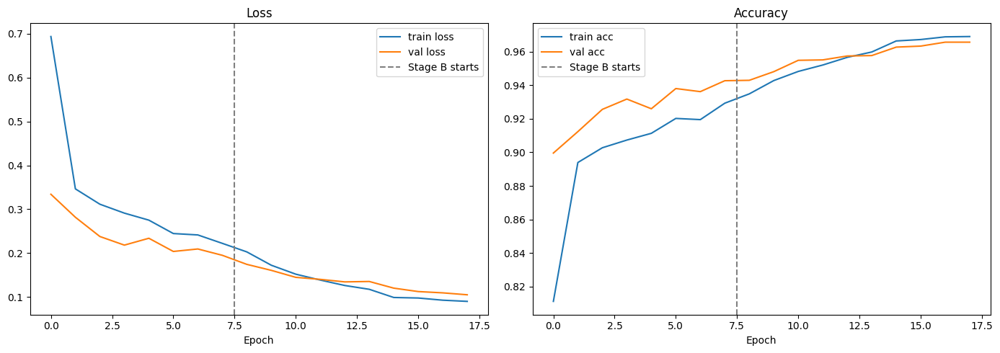

Final validation -> {'accuracy': 0.9656, 'loss': 0.1052, 'top3_acc': 0.9959}
Saved final model: /content/drive/MyDrive/leafscope-ai/models/leafscope_v1.keras


In [44]:
hist = pd.concat([
    pd.DataFrame(history_a.history).assign(stage="A"),
    pd.DataFrame(history_b.history).assign(stage="B"),
], ignore_index=True)
hist.to_csv(f"{PROJECT_DIR}/outputs/training_history.csv", index_label="epoch")

n_a = len(history_a.history["loss"])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(hist["loss"], label="train loss")
axes[0].plot(hist["val_loss"], label="val loss")
axes[0].axvline(n_a - 0.5, color="gray", linestyle="--", label="Stage B starts")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(hist["accuracy"], label="train acc")
axes[1].plot(hist["val_accuracy"], label="val acc")
axes[1].axvline(n_a - 0.5, color="gray", linestyle="--", label="Stage B starts")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
curves_path = f"{PROJECT_DIR}/outputs/training_curves.png"
plt.savefig(curves_path, dpi=150, bbox_inches="tight")
plt.show()

final_val = model.evaluate(val_ds, verbose=0, return_dict=True)
print("Final validation ->", {k: round(float(v), 4) for k, v in final_val.items()})

model_path = f"{PROJECT_DIR}/models/leafscope_v1.keras"
model.save(model_path)
print("Saved final model:", model_path)

if USE_MLFLOW:
    mlflow.log_metrics({f"final_val_{k}": float(v) for k, v in final_val.items()})
    mlflow.log_param("model_version", "v1")
    mlflow.log_artifact(curves_path)
    mlflow.end_run()
    print("MLflow run closed.")

In [45]:
import os, json
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras

PROJECT_DIR = "/content/drive/MyDrive/leafscope-ai"
MODEL_PATH = f"{PROJECT_DIR}/models/leafscope_v1.keras"
assert os.path.exists(MODEL_PATH), "leafscope_v1.keras not found. Finish training (Cells 31-35) first."

model = keras.models.load_model(MODEL_PATH)

with open(f"{PROJECT_DIR}/models/class_names.json") as f:
    class_names = json.load(f)

splits = pd.read_csv(f"{PROJECT_DIR}/data/splits.csv")
test_df = splits[splits["split"] == "test"].reset_index(drop=True)
assert os.path.exists(test_df.loc[0, "path"]), "Dataset missing in /content/data. Run Cell 5 again."

IMG_SIZE = 224

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, label

test_ds = (tf.data.Dataset.from_tensor_slices(
               (test_df["path"].tolist(), test_df["label"].values.astype("int32")))
           .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
           .batch(32)
           .prefetch(tf.data.AUTOTUNE))

print("Test images:", len(test_df), "| Classes:", len(class_names))

Test images: 8146 | Classes: 38


In [46]:
from sklearn.metrics import accuracy_score, f1_score

probs = model.predict(test_ds, verbose=1)
y_true = test_df["label"].values
y_pred = probs.argmax(axis=1)
assert len(probs) == len(y_true), "Prediction count does not match test labels."

top3 = np.argsort(probs, axis=1)[:, -3:]
top3_acc = np.mean([y_true[i] in top3[i] for i in range(len(y_true))])
acc = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
weighted_f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

print(f"Test accuracy : {acc:.4f}")
print(f"Top-3 accuracy: {top3_acc:.4f}")
print(f"Macro F1      : {macro_f1:.4f}")
print(f"Weighted F1   : {weighted_f1:.4f}")

np.save(f"{PROJECT_DIR}/outputs/test_probs.npy", probs)

255/255 ━━━━━━━━━━━━━━━━━━━━ 17s 62ms/step
Test accuracy : 0.9740
Top-3 accuracy: 0.9968
Macro F1      : 0.9687
Weighted F1   : 0.9740


Weakest 8 classes by recall:
                                                    precision  recall  \
Tomato___Early_blight                                   0.929   0.780   
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      0.919   0.883   
Tomato___Septoria_leaf_spot                             0.945   0.906   
Tomato___Target_Spot                                    0.834   0.929   
Tomato___Spider_mites Two-spotted_spider_mite           0.936   0.933   
Apple___Apple_scab                                      1.000   0.936   
Tomato___Late_blight                                    0.931   0.937   
Tomato___Leaf_Mold                                      0.925   0.944   

                                                    f1-score  support  
Tomato___Early_blight                                  0.848    150.0  
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.901     77.0  
Tomato___Septoria_leaf_spot                            0.925    265.0  
Tomato___Target_Spot     

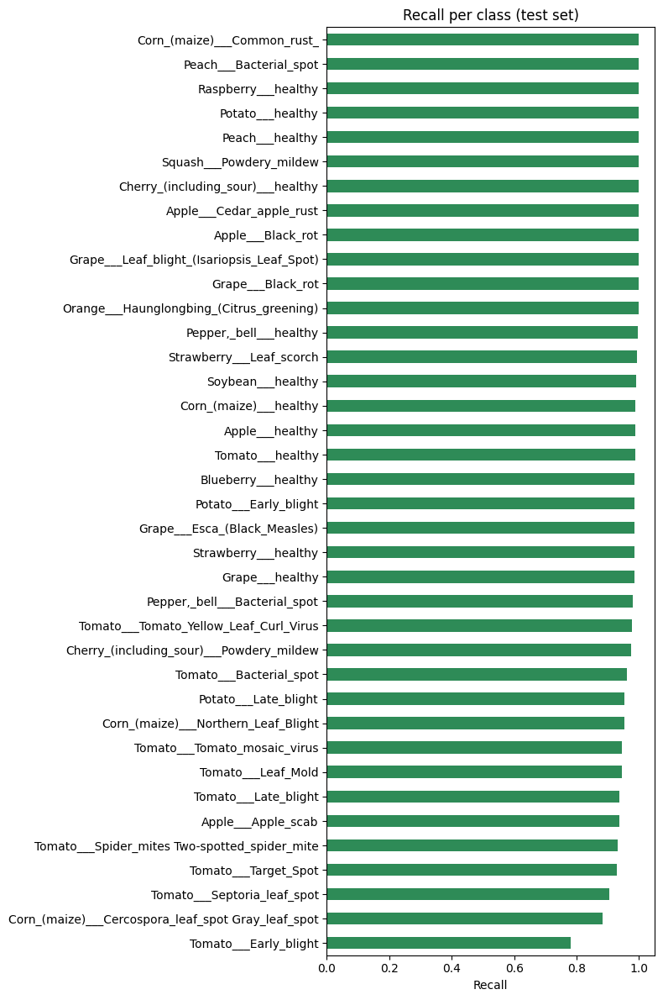

In [47]:
from sklearn.metrics import classification_report

labels_all = list(range(len(class_names)))
report = classification_report(y_true, y_pred, labels=labels_all,
                               target_names=class_names, output_dict=True, zero_division=0)
rep_df = pd.DataFrame(report).T.iloc[:len(class_names)]
rep_df.to_csv(f"{PROJECT_DIR}/outputs/per_class_report.csv")

print("Weakest 8 classes by recall:")
print(rep_df.sort_values("recall").head(8)[["precision", "recall", "f1-score", "support"]].round(3))

plt.figure(figsize=(8, 12))
rep_df.sort_values("recall")["recall"].plot(kind="barh", color="seagreen")
plt.title("Recall per class (test set)")
plt.xlabel("Recall")
plt.tight_layout()
plt.savefig(f"{PROJECT_DIR}/outputs/per_class_recall.png", dpi=150, bbox_inches="tight")
plt.show()

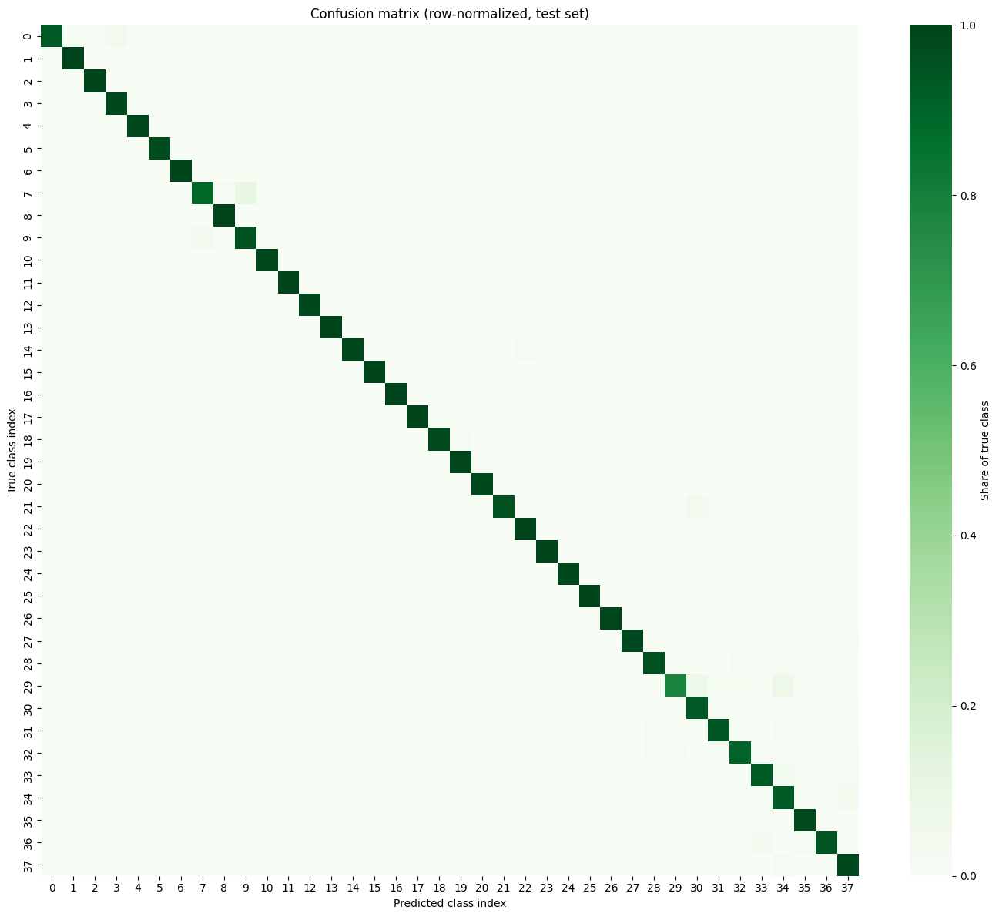

Most frequent mistakes:
 count                                         true class                                  predicted as
    12                              Tomato___Early_blight                          Tomato___Late_blight
    11      Tomato___Spider_mites Two-spotted_spider_mite                          Tomato___Target_Spot
    11                              Tomato___Early_blight                          Tomato___Target_Spot
     8 Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot           Corn_(maize)___Northern_Leaf_Blight
     7             Tomato___Tomato_Yellow_Leaf_Curl_Virus                       Tomato___Bacterial_spot
     6                               Tomato___Target_Spot                              Tomato___healthy
     6                            Tomato___Bacterial_spot                   Tomato___Septoria_leaf_spot
     5             Tomato___Tomato_Yellow_Leaf_Curl_Virus Tomato___Spider_mites Two-spotted_spider_mite
     5                        Tomato___S

In [48]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

n = len(class_names)
cm = confusion_matrix(y_true, y_pred, labels=labels_all)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(14, 12))
sns.heatmap(cm_norm, cmap="Greens", xticklabels=labels_all, yticklabels=labels_all,
            cbar_kws={"label": "Share of true class"})
plt.title("Confusion matrix (row-normalized, test set)")
plt.xlabel("Predicted class index")
plt.ylabel("True class index")
plt.tight_layout()
plt.savefig(f"{PROJECT_DIR}/outputs/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

pairs = []
for i in range(n):
    for j in range(n):
        if i != j and cm[i, j] > 0:
            pairs.append((int(cm[i, j]), class_names[i], class_names[j]))
pairs.sort(reverse=True)

top_pairs = pd.DataFrame(pairs[:10], columns=["count", "true class", "predicted as"])
top_pairs.to_csv(f"{PROJECT_DIR}/outputs/top_confusions.csv", index=False)
print("Most frequent mistakes:")
print(top_pairs.to_string(index=False))

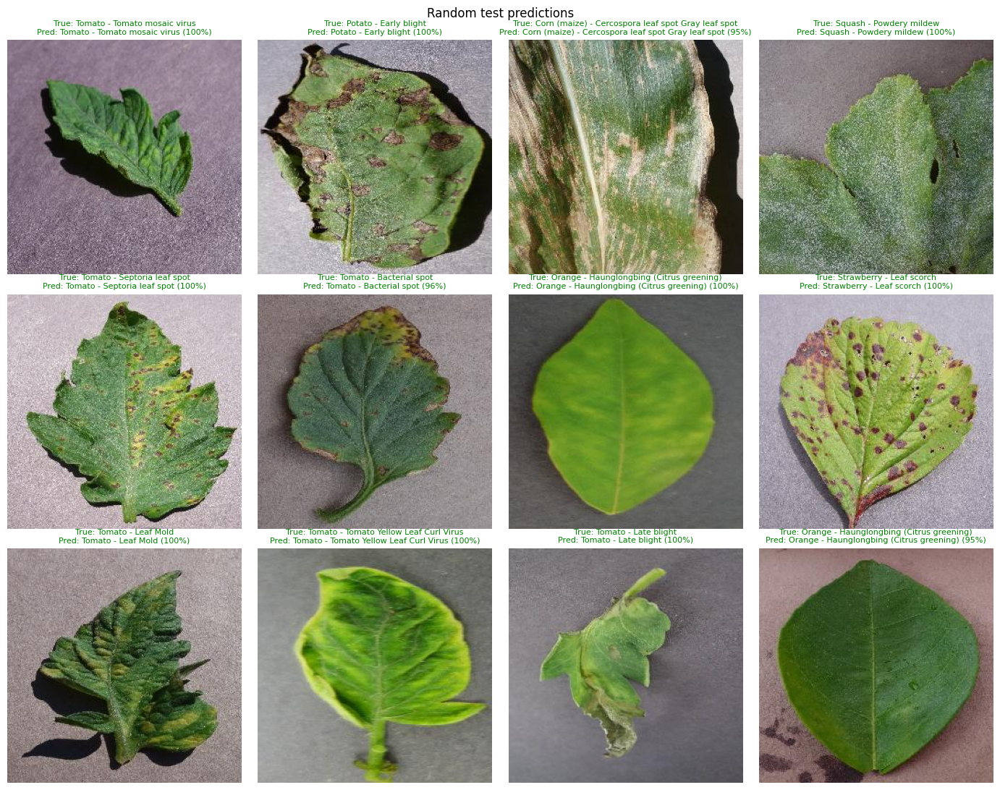

Total mistakes: 212 out of 8146


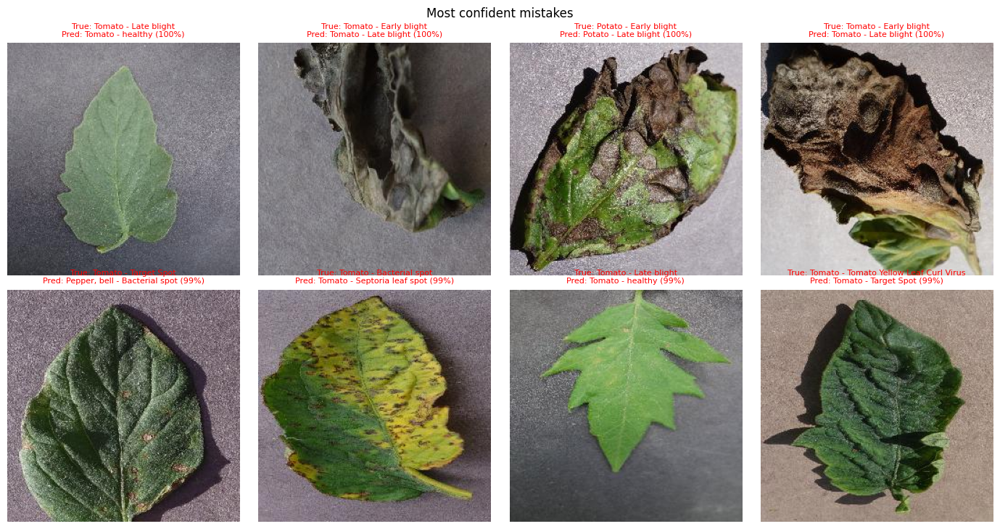

In [49]:
from PIL import Image

def short(name):
    return name.replace("___", " - ").replace("_", " ")

def draw_grid(indices, title, path):
    cols = 4
    rows = int(np.ceil(len(indices) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(14, 3.7 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, i in zip(axes, indices):
        p = y_pred[i]
        ok = p == y_true[i]
        ax.imshow(Image.open(test_df.loc[i, "path"]))
        ax.set_title(f"True: {short(class_names[y_true[i]])}\n"
                     f"Pred: {short(class_names[p])} ({probs[i, p] * 100:.0f}%)",
                     fontsize=8, color="green" if ok else "red")
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(path, dpi=130, bbox_inches="tight")
    plt.show()

rng = np.random.default_rng(42)
random_idx = rng.choice(len(test_df), 12, replace=False)
draw_grid(random_idx, "Random test predictions", f"{PROJECT_DIR}/outputs/sample_predictions.png")

wrong = np.where(y_pred != y_true)[0]
print("Total mistakes:", len(wrong), "out of", len(y_true))
if len(wrong) > 0:
    conf_wrong = probs[wrong, y_pred[wrong]]
    worst = wrong[np.argsort(-conf_wrong)[:8]]
    draw_grid(worst, "Most confident mistakes", f"{PROJECT_DIR}/outputs/confident_mistakes.png")

In [51]:
conf = probs.max(axis=1)
correct = y_pred == y_true

rows = []
for t in [0.5, 0.6, 0.7, 0.8, 0.9]:
    m = conf >= t
    rows.append({
        "threshold": t,
        "coverage_%": round(float(m.mean()) * 100, 1),
        "accuracy_%": round(float(correct[m].mean()) * 100, 2) if m.any() else None,
    })
thr_df = pd.DataFrame(rows)
print(thr_df.to_string(index=False))

baseline = {
    "source": "test set predictions of leafscope_v1",
    "n_images": int(len(conf)),
    "mean_confidence": float(conf.mean()),
    "median_confidence": float(np.median(conf)),
    "p05_confidence": float(np.percentile(conf, 5)),
    "mean_confidence_correct": float(conf[correct].mean()),
    "mean_confidence_wrong": float(conf[~correct].mean()) if (~correct).any() else None,
    "predicted_class_share": {class_names[i]: float(np.mean(y_pred == i)) for i in range(len(class_names))},
}
with open(f"{PROJECT_DIR}/models/baseline_stats.json", "w") as f:
    json.dump(baseline, f, indent=2)
print("Saved baseline_stats.json")

 threshold  coverage_%  accuracy_%
       0.5        99.5       97.70
       0.6        98.0       98.23
       0.7        96.3       98.78
       0.8        94.5       99.04
       0.9        91.1       99.41
Saved baseline_stats.json
